# ECE 3715 Mini-Project 1

## Probability, Bayes, and Discrete Random Variables
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: September 18, 2026

Due Date: October 9, 2026
## Objective
Use probability theory and Python simulations to analyze a wireless communication link. Each bit is independently corrupted by the channel with probability $p$. We will determine how these corrupted bits affect packet errors and retransmissions.

In [1]:

import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
from scipy import stats #Used for theoretical probabilities of binomial, poisson and geometric distribution
import matplotlib.pyplot as plt #Used for plotting graphs
import mp1lib as func #Functions from mp1lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 17                  #Our chosen seed number to keep rng consistent
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

In [2]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#For testing purposes we will use a different rng so it doesn't interfere with our current one
rng_test = numpy.random.default_rng(20)

#Setting a test array to test BSC function
b = numpy.array([0, 1, 0, 1, 0, 1, 1])
#Testing array with 0% probability, no bits will get corrupted
assert numpy.array_equal(func.bsc(b, 0, rng_test), b) #array_equal checks if both arrays are equal to each other and outputs t/f
#Testing array with 100% probability, will flip bit array
assert numpy.array_equal(func.bsc(b, 1, rng_test), 1 - b) #1-b Preforms a bit flip
print("BSC Test:        ", b ,"\n0% Probability:  ",func.bsc(b, 0, rng_test), "\n100% Probability:",func.bsc(b, 1.0, rng_test))

#Packet Error Test
#Testing packet error with 0% probability, each packet should contain 0 errors
assert numpy.all(func.packet_errors(5, 1000, 0, rng_test) == 0)
#Testing packet error with 100% probability, each packet should contain max amount of errors
assert numpy.all(func.packet_errors(5, 1000, 1.0, rng_test) == 1000)
print("Packet Errors Test:\n" "0% probability:  ", func.packet_errors(5, 1000, 0, rng_test), "\n100% probability:", func.packet_errors(5, 1000, 1, rng_test))

#Clean Attempt Test
#Testing attempts until clean with 100% probability of successful transmission, all test should be 1
assert numpy.all(func.attempts_until_clean(5, 1, rng_test) == 1)
#Testing 100,000 trials to make sure that our minimum attempt is 1 not 0, if not assert error will occur
assert func.attempts_until_clean(100000, 0.1, rng_test).min() >= 1
print("Clean Attempts Test:\n""q=1:", func.attempts_until_clean(5, 1, rng_test))

#TV Distance Test
#Identical test should have a 0 distance
assert func.tv_distance([0.2, 0.3, 0.5],[0.2, 0.3, 0.5]) == 0
#Complete opposite test should have max distance
assert func.tv_distance([1, 0, 0],[0, 0, 1]) == 1

print("TV Distance Test:\n""Identical distributions:",func.tv_distance([0.2, 0.3, 0.5], [0.2, 0.3, 0.5]),"\nOpposite distributions: ",
    func.tv_distance([1, 0, 0], [0, 0, 1]))

print("\nAll functions work as expected!")

BSC Test:         [0 1 0 1 0 1 1] 
0% Probability:   [0 1 0 1 0 1 1] 
100% Probability: [1 0 1 0 1 0 0]
Packet Errors Test:
0% probability:   [0 0 0 0 0] 
100% probability: [1000 1000 1000 1000 1000]
Clean Attempts Test:
q=1: [1 1 1 1 1]
TV Distance Test:
Identical distributions: 0.0 
Opposite distributions:  1.0

All functions work as expected!


## Step 1: The Sample Space and The Axioms

**Objective:** Analyze the probabilities of different event spaces (A, B, C) for a 4 bit packet.

- **A**: At lest one error among the first two bits
- **B**: Exactly two errors in the packet
- **C**: The fourth bit is corrupted

For a 4 bit packet there are $2^4=16$ unique patterns. The probability of a specific case with $k$ errors is


$$P(\text{patterns})=p^k(1-p)^{4-k}$$


- **k** = number of corrupted bits (the error)
- **p** = probability of corruption

The probability of the 16 patterns should sum up to 1. 

**Process:** We will generate all 16 possibilities for a 4 bit packet and determine the probabilities of 3 event conditions (A, B and C). Each bit has a 10% probability of being corrupted (**p** = 0.1). A 1 will represent the corrupted bit while a 0 represents an uncorrupted bit.

In [3]:
from itertools import product

p1 = 0.1 #10% probability for step 1

#Creating an array of all 16 patterns
patterns = numpy.array(list(product([0, 1], repeat=4)))#An array of all possible outcomes for 4 bits

#Figuring the number of errors in each packet by summing the bits in each row
error_count = patterns.sum(axis=1) #An array of all error counts in each packet

#Probability of a specific case happening
prob_form = (p1 ** error_count * (1 - p1) ** (4 - error_count))

print(patterns)
print("Sum of probabilities:", prob_form.sum()) #Sum of all probabilities should be 1

[[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]
Sum of probabilities: 0.9999999999999999


### Event Space Probabilities
We will hand calculate the event spaces below with 10% probability of a bit being corrupted
$$P(\text{patterns})=p^k(1-p)^{n-k}$$


- **k** = number of corrupted bits (the error)
- **p** = probability of corruption
- **n**: Number of bits

**Event A**: At least one error among the first two bits
$$P([1,0,0,0])=0.1(0.9)^3=0.0729$$
$$P([1,0,0,1])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,0,1,0])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,0,1,1])=(0.1)^3(0.9)=0.0009$$
$$0.0729+0.0081+0.0081+0.0009=0.09$$
$$P([1,1,0,0])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,1,0,1])=(0.1)^3(0.9)^1=0.0009$$
$$P([1,1,1,0])=(0.1)^3(0.9)^1=0.0009$$
$$P([1,1,1,1])=(0.1)^4(0.9)^0=0.0001$$
$$0.0081+0.0009+0.0009+0.0001=0.01$$

Multiply 0.09 * 2 because there are the same amount of possible combinations for the bits [0, 1]
$$P(A)=2 \cdot 0.09+0.01$$

$$P(A)=0.19$$

**Event B:** Exactly two errors in the four bit packet

We can use the Binomial PMF to calculate for all possible packets with 2 errors

Binomial PMF: $$P(B)=\binom{n}{k}p^k(1-p)^{n-k}$$
$$P(B)=\binom{4}{2}p^2(1-p)^{4-2}$$

$$P(B)=\binom{4}{2}(0.1)^2(0.9)^2$$

$$P(B)=6(0.01)(0.81)$$

$$P(B)=0.0486$$

**Event C:** The fourth bit is corrupted

Since each bit has a probability of 10% corruption, the fourth bit will follow the same pattern

$$P(C)=p$$

$$P(C)=0.1$$


In [4]:
#Computing the event space

#A: At least one error among the first two bits
A = patterns[:, 0:2].any(axis=1)

#B: Exactly two errors in the entire packet
B = patterns.sum(axis=1) == 2

# C:The fourth bit is corrupted
C = patterns[:, 3] == 1

#Exact Probabilities of individual events
ProbA_exact = prob_form[A].sum()
ProbB_exact = prob_form[B].sum()
ProbC_exact = prob_form[C].sum()

print("P(A): ", round(ProbA_exact, 4))
print("P(B): ", round(ProbB_exact.sum(), 4))
print("P(C): ", round(ProbC_exact.sum(), 4))

P(A):  0.19
P(B):  0.0486
P(C):  0.1


### Monte Carlo Simulation
Objective: To test our probabilities we will use the Monte Carlo Simulation for all three event (A, B, C). Monte Carlo simulation is a method that runs a random experiment many times (in our simulation $N=10^6$ four bit packets) so we can get a close estimate of each event probability if each bit has a 10% chance of getting corrupted. 

Process:

We will estimate each event probability by dividing the number of packets in the event by the total number of simulated packets:

$$\widehat{P}(Event)=\frac{\text{number packets in }Event}{N}$$

$$\widehat{P}(\text{Event})=
\frac{1}{N}\sum_{i=1}^{N}
\mathbf{1}\{\text{event occurs in trial }i\}$$

Both formulas represent the same thing.

More trials will improve the estimated probabilities but we are doing 1 million packets so we will get close.

In [5]:
#Monte Carlo simulation
N = 10**6 #1 million trials

#Simulate 1 million trials, creates an array of 1 million rows with all 0, run through bsc to simulate corruption
sim_patterns = func.bsc(numpy.zeros((N, 4), dtype=int),p1,rng1) 

#Event Packet checker, stores an array of T/F for each packet, True means it's in the Event
Check_A = sim_patterns[:, 0:2].any(axis=1) #Checks the first two columns of each row if any contain a corrupted bit
Check_B = sim_patterns.sum(axis=1) == 2 #Checks every row if it contains exactly 2 corrupted bits
Check_C = sim_patterns[:, 3] == 1 #Checks the last column if it contains a corrupted bit

#Calculates the probability of each event using the mean. Basically the number of packets in the Event by total trials.
ProbA_sim = Check_A.mean()
ProbB_sim = Check_B.mean()
ProbC_sim = Check_C.mean()

#Output Monte Carlo simulation results
print("Monte Carlo estimates:")
print("P(A): ", round(ProbA_sim, 4))
print("P(B): ", round(ProbB_sim, 4))
print("P(C): ", round(ProbC_sim, 4))

Monte Carlo estimates:
P(A):  0.1905
P(B):  0.0487
P(C):  0.1001


### Event Intersections Exact and Empirical 

An event intersection means that both events occur at the same time. For a triple intersection all three events must occur at the same time. 

It is mathematically below depicted with probability encasing it.

Pairwise Intersections:
$$P(A\cap B) \qquad P(A\cap C) \qquad (B\cap C)$$

Triple Inteserction:
$$P(A\cap B\cap C)$$

In [6]:
#Exact and Empirical Intersection Calculations

#Exact intersection probabilities
ProbAB_exact = prob_form[A & B].sum()
ProbAC_exact = prob_form[A & C].sum()
ProbBC_exact = prob_form[B & C].sum()
ProbABC_exact = prob_form[A & B & C].sum()

#Checking if packets intersect
Check_AB = Check_A & Check_B
Check_AC = Check_A & Check_C
Check_BC = Check_B & Check_C
Check_ABC = Check_A & Check_B & Check_C

#Empirical intersection probabilities
ProbAB_sim = Check_AB.mean()
ProbAC_sim = Check_AC.mean()
ProbBC_sim = Check_BC.mean()
ProbABC_sim = Check_ABC.mean()

#Output the Exact and Empirical Intersection results
print("Intersection probabilities:")
print("              Exact      Empirical")
print("P(A and B):  ", round(ProbAB_exact, 4), "   ", round(ProbAB_sim, 4))
print("P(A and C):  ", round(ProbAC_exact, 4), "    ", round(ProbAC_sim, 4))
print("P(B and C):  ", round(ProbBC_exact, 4), "   ", round(ProbBC_sim, 4))
print("P(A, B, C):  ", round(ProbABC_exact, 4), "   ", round(ProbABC_sim, 4))

Intersection probabilities:
              Exact      Empirical
P(A and B):   0.0405     0.0407
P(A and C):   0.019      0.0191
P(B and C):   0.0243     0.0242
P(A, B, C):   0.0162     0.0163


### Inclusion-Exclusion

An inclusion exclusion means that one or the other event must occur. It can be thought of as an or statement. 

It is mathematically depicted below with probability encasing it.

$$P(A\cup B\cup C)=P(A)+P(B)+P(C)-P(A\cap B)-P(A\cap C)-P(B\cap C)+P(A\cap B\cap C).$$

The full equation shows the inclusion and exclusion method. The method is to add all individual probability togehter. Since adding them together causes overlap we must subtract the three pairwise intersections to remove duplicated counts. Then we must add the triple intersection because the subtraction takes away some counts.

In [7]:
#Inclusion Exclusion Calculation

#Exact or calculation
ProbOR_exact = prob_form[A | B | C].sum()

#Exact inclusion exclusion
ProbIE_exact = (ProbA_exact + ProbB_exact + ProbC_exact - ProbAB_exact - ProbAC_exact - ProbBC_exact + ProbABC_exact)

#Checking if each packet is in the union
Check_union = Check_A | Check_B | Check_C

#Empirical union calculation
ProbOR_sim = Check_union.mean()

#Empirical union calculated with inclusion exclusion
ProbIE_sim = (ProbA_sim + ProbB_sim + ProbC_sim - ProbAB_sim - ProbAC_sim - ProbBC_sim + ProbABC_sim)

#Output Exact and Empircal Results of 
print("Union probabilities:")
print("                         Exact       Empirical")
print("Direct calculation:     ", round(ProbOR_exact, 4),"     ", round(ProbOR_sim, 4))
print("Inclusion-exclusion:    ", round(ProbIE_exact, 4),"     ", round(ProbIE_sim, 4))
print("\nDifference between exact methods:", abs(ProbOR_exact - ProbIE_exact))
print("Difference between empirical methods:", round(abs(ProbOR_sim - ProbIE_sim), 4))

Union probabilities:
                         Exact       Empirical
Direct calculation:      0.271       0.2715
Inclusion-exclusion:     0.271       0.2715

Difference between exact methods: 0.0
Difference between empirical methods: 0.0


### Standard Error and Confirmation

**Objective:** Compare the empirical and actual probabilities of the events and confirm that they are within three standard errors. The actual probabilites are calculations while the empirical are taken from the Monte Carlo simulation.

The Monte Carlo simulation uses $N=10^6$ packets. Since the probability is an estimation using simulation their answers can be slightly different which is why we are verifying our solutions.

For an estimated probability $\widehat{P}$, the standard error is

$$
SE=\sqrt{\frac{\widehat{P}(1-\widehat{P})}{N}}
$$

- $\widehat{P}$ = empirical probability
- $N$ = total number of packets

To calculate the absolute difference between probabilities the equation is shown below:

$$
\text{difference}=\left|\widehat{P}-P\right|
$$

- $P$ = exact probability

**Process:** We will compare the difference within three standard errors for the individual events, pairwise intersections, triple intersection, and union.

In order for our results to be verified we must follow the difference criteria below. If all differences follow the critieria that means the empirical probabilities is very close to the actual probabilities. 
$$
\text{difference}\leq 3SE
$$

In [8]:
#Array of exact probabilities
exact_probs = numpy.array([ProbA_exact, ProbB_exact, ProbC_exact, ProbAB_exact, ProbAC_exact, ProbBC_exact, ProbABC_exact, ProbOR_exact])

#Array of empirical probabilities
empirical_probs = numpy.array([ProbA_sim, ProbB_sim, ProbC_sim, ProbAB_sim, ProbAC_sim, ProbBC_sim, ProbABC_sim, ProbOR_sim])

#Standard error calculation for emprirical v
standard_errors = numpy.sqrt(empirical_probs * (1 - empirical_probs) / N)

diff = numpy.abs(empirical_probs - exact_probs)

within_three_SE = diff <= 3 * standard_errors

print("Event              Exact       Empirical       Difference       SE         Within 3 SE")
print("A:                 ", round(exact_probs[0], 4), "      ", round(empirical_probs[0], 4), "       ", round(diff[0], 6), "       ", round(standard_errors[0], 6), "    ", within_three_SE[0])
print("B:                 ", round(exact_probs[1], 4), "    ", round(empirical_probs[1], 4), "       ", round(diff[1], 6), "       ", round(standard_errors[1], 6), "    ", within_three_SE[1])
print("C:                 ", round(exact_probs[2], 4), "       ", round(empirical_probs[2], 4), "       ", round(diff[2], 6), "        ", round(standard_errors[2], 6), "      ", within_three_SE[2])
print("A and B:           ", round(exact_probs[3], 4), "    ", round(empirical_probs[3], 4), "       ", round(diff[3], 6), "        ", round(standard_errors[3], 6), "    ", within_three_SE[3])
print("A and C:           ", round(exact_probs[4], 4), "     ", round(empirical_probs[4], 4), "       ", round(diff[4], 6), "       ", round(standard_errors[4], 6), "    ", within_three_SE[4])
print("B and C:           ", round(exact_probs[5], 4), "    ", round(empirical_probs[5], 4), "       ", round(diff[5], 6), "        ", round(standard_errors[5], 6), "    ", within_three_SE[5])
print("A, B, and C:       ", round(exact_probs[6], 4), "    ", round(empirical_probs[6], 4), "       ", round(diff[6], 6), "        ", round(standard_errors[6], 6), "    ", within_three_SE[6])
print("A or B or C:       ", round(exact_probs[7], 4), "     ", round(empirical_probs[7], 4), "       ", round(diff[7], 6), "       ", round(standard_errors[7], 6), "    ", within_three_SE[7])

Event              Exact       Empirical       Difference       SE         Within 3 SE
A:                  0.19        0.1905         0.000496         0.000393      True
B:                  0.0486      0.0487         0.000108         0.000215      True
C:                  0.1         0.1001         7.4e-05          0.0003        True
A and B:            0.0405      0.0407         0.00021          0.000198      True
A and C:            0.019       0.0191         0.000104         0.000137      True
B and C:            0.0243      0.0242         5.1e-05          0.000154      True
A, B, and C:        0.0162      0.0163         5.1e-05          0.000126      True
A or B or C:        0.271       0.2715         0.000466         0.000445      True


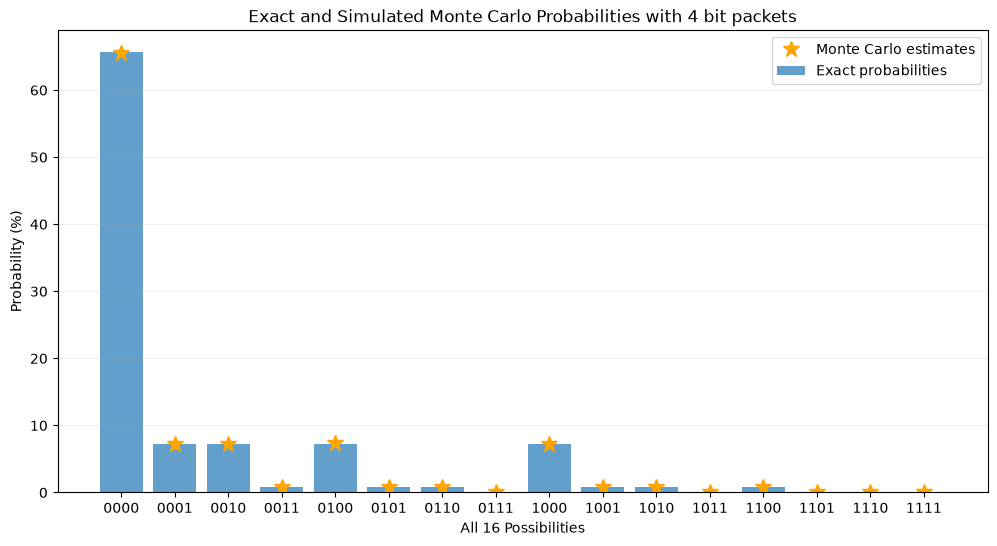

In [9]:
#Plot for Exact and Empirical probabilities of all 16 four bit combinations

#Assign each index in the array an index value so we can count how many times they appeared
pattern_index = sim_patterns[:, 0] * 8 + sim_patterns[:, 1] * 4 + sim_patterns[:, 2] * 2 + sim_patterns[:, 3]

#Counter for each array index divided by N to get empirical probability of each pattern
i_emp_prob = numpy.bincount(pattern_index, minlength=16) / N

#X-Axis lables for all 16 four bit combinations
fourbit_x_labels = ["".join(str(bit) for bit in pattern) for pattern in patterns]

#Creates x axis positions all 16 patterns
x = numpy.arange(16)

#Graph dimensions
plt.figure(figsize=(12, 6))

#Exact probabilities as a bar chart
plt.bar(x, prob_form*100, alpha=0.7, label="Exact probabilities")

#Plots Monte Carlo probabilities as markers
plt.plot(x, i_emp_prob*100, "*", color="orange", markersize =12, label="Monte Carlo estimates")

#Adds labels and formatting
plt.xticks(x, fourbit_x_labels)
plt.xlabel("All 16 Possibilities")
plt.ylabel("Probability (%)")
plt.title("Exact and Simulated Monte Carlo Probabilities with 4 bit packets")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

### Figure 1 Explanation

    The bars in the graph depict the exact probability for all 16 four bit combinations while the orange star markers depict the empirical probabilities from the Monte Carlo simulation with 1 million packets. The 0000 pattern is the most prominent because each bit only has a 10% probability of getting corrupted. In the graph you will notice that both probabilities are close to each other for their respective pattern. The reason for any differences is because the simulation is a collection of random data used to estimate probability. The simulation only provides an estimate not the exact probability. 


### Step 1 Conclusion

    Step 1 analyzed all 16 four bit patterns and calculated the different events with each bit having a 10% probability of being corrupted. We found the probability of at least one error among the first two bits, exactly two errors in the packets and probability of the fourth bit being corrupted. Then we simulated via Monte Carlo with 1 million packets. Since we did so many packets our probabilities were really close in value resulting in less than 3 standard errors between datasets. We did the same for pairwise intersections, triple intersection, and union analyzing exact probability and empirical. After gathering all of the probabilities we created a table to organize the data and display the differences between them. We showed that the empirical probabilities were within three standard deviation of the exact probability which shows that they were close estimates of the exact. Overall, we were able to successfully find the exact probability and show that the Monte Carlo simulation works.

## Step 2: Conditional Probability and Bayes

**Objective:** Analyze the probability that a bit is actually corrupted when a flagging circuit raises a flag.

- $p$ = prior probability that a bit is corrupted

The prior probability represents the initial probability of corruption before we analyzing the flagging circuit.

**Process:** We will use Bayes theorem to calculate the probability that a bit is actually corrupted when the flagging circuit raises a flag. We will test different prior probabilities and visualize how changing $p$ affects the actual probability.

### Bayes Theorem Derivation

In order to find the probability that a bit is actually corrupted when the flagging circuit raises a flag, we can use Bayes theorem.
The general Bayes theorem is

$$P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}$$

- $A$ = the bit is corrupted
- $A'$ = the bit is not corrupted
- $B$ = the flagging circuit raises a flag

----------

The flagging circuit has two probabilities:
1. $P(B\mid A)=0.95$ = the circuit raises a flag given that the bit is corrupted
2. $P(B\mid A')=0.02$ = the circuit raises a flag given that the bit is not corrupted

The first probability means there is a 95% chance of correctly flagging a bit that is corrupted. The second probability means there is a 2% chance of accidentally flagging a bit that isn't corrupted.

----------

To find the probability of a flag occuring we can sum the probabilities of when it raises for each case.

$$P(B)=P(B\mid A)P(A)+P(B\mid A')P(A')$$

For 

$$ P(A)=p \qquad P(A')=1-p \qquad P(B\mid A)=0.95 \qquad P(B\mid A')=0.02 $$

$$P(B)=0.95p+0.02(1-p)$$
The probability of B ( P(B) ) is the total probability of a flag occuring considering both casses based on the prior.

Substituting this into Bayes theorem gives

$$P(A\mid B)=\frac{0.95p}{0.95p+0.02(1-p)}$$

The formula gives the posterior probability that a bit is corrupted given the flag conditions.

In [10]:
#Calculates the probability that a bit is actually corrupted when the circuit raises a flag
def posterior_prob(p):
    return (0.95 * p) / (0.95 * p + 0.02 * (1 - p))

#The posterior probabilities given 3 different prior probabilities
print("p = 0.1,   P(corrupted | flag) =", round(posterior_prob(0.1), 4))
print("p = 0.01,  P(corrupted | flag) =", round(posterior_prob(0.01), 4))
print("p = 0.001, P(corrupted | flag) =", round(posterior_prob(0.001), 4))

p = 0.1,   P(corrupted | flag) = 0.8407
p = 0.01,  P(corrupted | flag) = 0.3242
p = 0.001, P(corrupted | flag) = 0.0454


### Posterior Probability as a Function of the Prior

The posterior probability changes as the prior bit-error probability $p$
changes. The horizontal axis will use a logarithmic scale because the prior
varies from $10^{-4}$ to $10^{-1}$.

Crossover p = 0.0206
Posterior at crossover = 0.5000


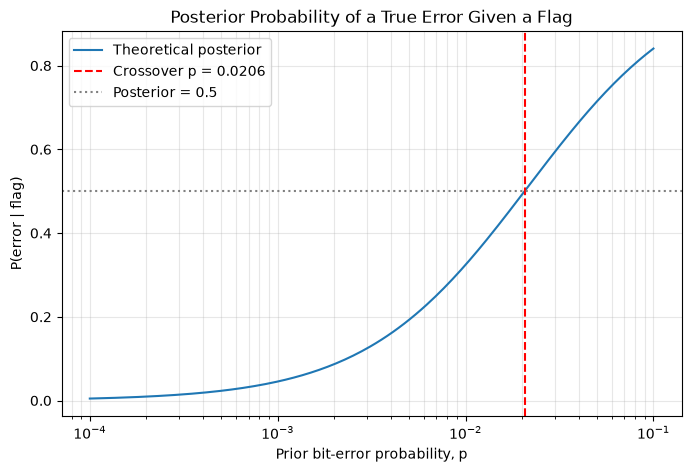

In [14]:
# Prior probabilities from 10^-4 to 10^-1
p_grid = numpy.logspace(-4, -1, 200)

# Calculate the posterior for every prior probability
posterior_values = posterior_prob(p_grid)

# Solve P(error | flag) = 0.5
p_crossover = 0.02 / (0.95 + 0.02)
posterior_crossover = posterior_prob(p_crossover)

print(f"Crossover p = {p_crossover:.4f}")
print(f"Posterior at crossover = {posterior_crossover:.4f}")

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Posterior Probability of a True Error Given a Flag")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Monte Carlo 

The theoretical crossover occurs when

$$
P(\text{error}\mid\text{flag})=0.5.
$$

Solving this equation gives

$$
0.5=
\frac{0.95p}{0.95p+0.02(1-p)}.
$$

Multiplying both sides by the denominator,

$$
0.5\left[0.95p+0.02(1-p)\right]=0.95p.
$$

This simplifies to

$$
0.02(1-p)=0.95p,
$$

so

$$
p=\frac{0.02}{0.95+0.02}
\approx 0.0206.
$$

We now verify this result by simulating $10^7$ bits.

In [15]:
# Monte Carlo verification of the crossover
N_bayes = 10_000_000

# Use the crossover probability
true_errors = rng2.random(N_bayes) < p_crossover

# The flag probability depends on whether an actual error occurred
flag_probabilities = numpy.where(
    true_errors,
    0.95,
    0.02
)

flags = rng2.random(N_bayes) < flag_probabilities

# Count flags and flags that correspond to true errors
number_of_flags = flags.sum()
number_of_true_error_flags = numpy.sum(flags & true_errors)

# Empirical posterior
posterior_estimate = (
    number_of_true_error_flags / number_of_flags
)

# Standard error of the conditional proportion
posterior_standard_error = numpy.sqrt(
    posterior_estimate
    * (1 - posterior_estimate)
    / number_of_flags
)

print(f"Number of flags: {number_of_flags}")
print(f"True-error flags: {number_of_true_error_flags}")
print(f"Empirical posterior: {posterior_estimate:.4f}")
print(f"Standard error: {posterior_standard_error:.4e}")
print(f"Theoretical posterior: {posterior_crossover:.4f}")

Number of flags: 391752
True-error flags: 196289
Empirical posterior: 0.5011
Standard error: 7.9885e-04
Theoretical posterior: 0.5000


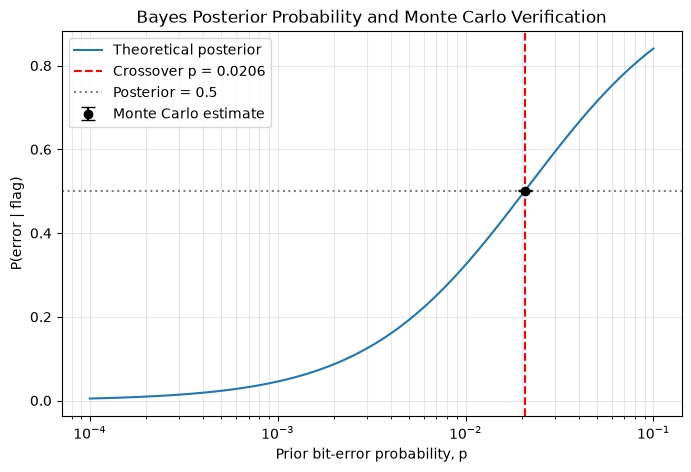

In [16]:
# Add the Monte Carlo estimate and error bar to the posterior plot

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.errorbar(
    p_crossover,
    posterior_estimate,
    yerr=posterior_standard_error,
    fmt="o",
    color="black",
    capsize=5,
    label="Monte Carlo estimate"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Bayes Posterior Probability and Monte Carlo Verification")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Conclusion

Although the flagging circuit detects $95\%$ of actual errors, a flag does not
always mean that an error occurred. When the link is very reliable, actual
errors are rare, so false flags can make up a large portion of all flags. For
example, when $p=0.001$, the probability that a flagged bit is actually
corrupted is only about $0.0453$. Therefore, the prior error rate must be
considered when interpreting a flag.

## Step 3: Independence

This step examines pairwise independence, mutual independence, and
conditional independence.

### Part 1: Pairwise and Mutual Independence

Two fair coins are flipped. Define the events:

- $E_1$: the first coin lands heads.
- $E_2$: the second coin lands heads.
- $E_3$: the two coins match.

Each event has probability

$$
P(E_1)=P(E_2)=P(E_3)=\frac{1}{2}.
$$

For pairwise independence, we compare the joint probabilities with the
products of the individual probabilities:

$$
P(E_1\cap E_2)=P(E_1)P(E_2),
$$

$$
P(E_1\cap E_3)=P(E_1)P(E_3),
$$

and

$$
P(E_2\cap E_3)=P(E_2)P(E_3).
$$

However,

$$
P(E_1\cap E_2\cap E_3)=\frac{1}{4},
$$

while

$$
P(E_1)P(E_2)P(E_3)
=
\frac{1}{2}\frac{1}{2}\frac{1}{2}
=
\frac{1}{8}.
$$

Therefore, the events are pairwise independent but not mutually
independent.

In [ ]:
# Part 1: two fair coins
N_coins = 1_000_000

coin_flips = rng3.integers(
    0,
    2,
    size=(N_coins, 2)
)

E1 = coin_flips[:, 0] == 1
E2 = coin_flips[:, 1] == 1
E3 = coin_flips[:, 0] == coin_flips[:, 1]

P_E1 = E1.mean()
P_E2 = E2.mean()
P_E3 = E3.mean()

P_E1E2 = (E1 & E2).mean()
P_E1E3 = (E1 & E3).mean()
P_E2E3 = (E2 & E3).mean()
P_E1E2E3 = (E1 & E2 & E3).mean()

print(f"P(E1) = {P_E1:.4f}")
print(f"P(E2) = {P_E2:.4f}")
print(f"P(E3) = {P_E3:.4f}")

print("\nPairwise comparisons:")
print(
    f"P(E1)P(E2) = {P_E1 * P_E2:.4f}, "
    f"P(E1 and E2) = {P_E1E2:.4f}"
)
print(
    f"P(E1)P(E3) = {P_E1 * P_E3:.4f}, "
    f"P(E1 and E3) = {P_E1E3:.4f}"
)
print(
    f"P(E2)P(E3) = {P_E2 * P_E3:.4f}, "
    f"P(E2 and E3) = {P_E2E3:.4f}"
)

print("\nTriple comparison:")
print(
    f"P(E1)P(E2)P(E3) = "
    f"{P_E1 * P_E2 * P_E3:.4f}, "
    f"P(E1 and E2 and E3) = {P_E1E2E3:.4f}"
)

### Part 2: Conditional Independence of Receiver Outputs

A transmitted bit is equally likely to be 0 or 1. Two receivers observe the
bit through independent channels. Receiver 1 has error probability $0.1$, and
Receiver 2 has error probability $0.3$.

The receiver outputs are dependent when the transmitted bit is unknown because
both receivers share the same transmitted bit. However, after conditioning
on the transmitted bit, the channel errors are independent. Therefore, the
conditional correlations should be approximately zero.

In [ ]:
# Part 2: two receivers observing the same transmitted bit
N_receivers = 1_000_000

transmitted_bits = rng3.integers(
    0,
    2,
    size=N_receivers
)

receiver_1_errors = rng3.random(N_receivers) < 0.1
receiver_2_errors = rng3.random(N_receivers) < 0.3

receiver_1_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_1_errors.astype(int)
)

receiver_2_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_2_errors.astype(int)
)


def correlation_and_standard_error(x, y):
    """Return Pearson correlation and its approximate standard error."""
    correlation = numpy.corrcoef(x, y)[0, 1]
    sample_size = len(x)
    standard_error = (
        1 - correlation**2
    ) / numpy.sqrt(sample_size - 2)
    return correlation, standard_error


# Unconditional correlation
rho_all, se_all = correlation_and_standard_error(
    receiver_1_output,
    receiver_2_output
)

# Correlation conditioned on transmitted bit = 0
mask_zero = transmitted_bits == 0
rho_zero, se_zero = correlation_and_standard_error(
    receiver_1_output[mask_zero],
    receiver_2_output[mask_zero]
)

# Correlation conditioned on transmitted bit = 1
mask_one = transmitted_bits == 1
rho_one, se_one = correlation_and_standard_error(
    receiver_1_output[mask_one],
    receiver_2_output[mask_one]
)

print(f"Unconditional correlation: {rho_all:.4f}")
print(f"Unconditional standard error: {se_all:.4e}")

print(f"\nCorrelation given transmitted bit = 0: {rho_zero:.4f}")
print(f"Standard error given transmitted bit = 0: {se_zero:.4e}")

print(f"\nCorrelation given transmitted bit = 1: {rho_one:.4f}")
print(f"Standard error given transmitted bit = 1: {se_one:.4e}")

print(f"\nSamples with transmitted bit = 0: {mask_zero.sum()}")
print(f"Samples with transmitted bit = 1: {mask_one.sum()}")

### Part 3: Conclusion

If two sensors share a common cause but are incorrectly assumed to be
independent, a fusion system may become overconfident in its result. It may
count the same information twice and underestimate the uncertainty of its
decision.

## Step 4: Bernoulli Trials and the Binomial

The goal of this step is to get from single bit behavior to packet-level behavior 

In [ ]:
def packet_errors(n_pkt, n_bits, p, rng, chunk=10_000):
    """Number of bit errors in each of n_pkt packets of n_bits bits.

    Each bit is in error independently with probability p.
    Simulated at the bit level, in chunks of packets to limit memory.
    Returns an int array of length n_pkt.
    """
    out = numpy.empty(n_pkt, dtype=numpy.int64)
    for s in range(0, n_pkt, chunk):
        m = min(chunk, n_pkt - s)
        out[s:s+m] = (rng.random((m, n_bits)) < p).sum(axis=1)
    return out

### Why Number of Errors in a 1000-bit Packet is binomial
Each of the n = 1000 bits is a Bernoulli trial that is in error with the same probability p, 
and the channel corrupts bits independently of one another. The error count is therefore a
sum of n i.i.d. Bernoulli(p) variables, which is by definition Binomial(n, p), with pmf 
$P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$

In [ ]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = plt.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, stats.binom.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

In [ ]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = plt.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, stats.binom.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

### Step 5: The Poisson Approximation
Goal: Establish when you are allowed to replace the Binomial with the simpler Poisson, 
quantitatively rather than by folklore. 

Brief Description/Intro to Step:
The Poisson approximation method can be used to approximate the number of events that occur over a period of time, assuming the rate of events is relatively constant. The formula shown above is the equation used for the total variation distance function. It is half the sum over all k (number of errors) of the absolute difference between the two probability mass functions. The above formula is used to quantify the difference between the probability results from Binomial distribution analysis vs. Poisson distribution analysis.

## Part 1:
Total variation distance measures how different two probability distributions are. We calculate it by taking the absolute difference between their probabilities at each error count $k$, adding these differences, and multiplying the sum by one half.

$d_{\mathrm{TV}}(P,Q) = 0.5\sum_{k=0}^{\infty}\left|P(k)-Q(k)\right|$

In [ ]:
# Part 1: Total Variation Distance Tests
pmf1 = numpy.array([0.2, 0.5, 0.3])
pmf2 = numpy.array([0.2, 0.5, 0.3])
pmf3 = numpy.array([1.0, 0.0, 0.0])
pmf4 = numpy.array([0.0, 0.5, 0.5])

assert func.tv_distance(pmf1, pmf2) == 0.0
assert func.tv_distance(pmf3, pmf4) == 1.0
print("Identical PMFs:", func.tv_distance(pmf1, pmf2))
print("Disjoint support:", func.tv_distance(pmf3, pmf4))

As we can see from our test results, the identical PMFs output an expected value of 0, indicating no difference while the disjoint support output 1, indicating the probabilities are not related in any way.


Total variation distance measures how different two probability
distributions are:

$$
d_{\mathrm{TV}}(P,Q)
=\frac{1}{2}\sum_k |P(k)-Q(k)|.
$$

We subtract the probabilities at each outcome, take their absolute
differences, add them, and divide by two.

For identical PMFs, we use as an example: $P=Q=[0.2,0.5,0.3]$:

$$
d_{\mathrm{TV}}
=\frac{1}{2}\left(
|0.2-0.2|+|0.5-0.5|+|0.3-0.3|
\right)=0.
$$

For disjoint PMFs, we use as an example: $P=[1,0,0]$ and $Q=[0,0.5,0.5]$:

$$
d_{\mathrm{TV}}
=\frac{1}{2}\left(
|1-0|+|0-0.5|+|0-0.5|
\right)
$$

$$
=\frac{1}{2}(1+0.5+0.5)=1.
$$

These tests check that our function returns zero for identical
distributions and one for distributions with no overlap.

## Part 2:
Since Poisson becomes closer to the binomial method as probability p is lower and n number of independent trials increases, we calculate for the poisson process up to K number of errors. Probabilities for more than K errors are the leftover tail, which are required to be below \(10^{-12}\) probability. \(k\) is an individual error count, while \(K\) is the cutoff chosen. Setting K at the mean + 20 standard deviations + an additional factor of 20 ensures that our chance of encountering an error very low, as we account for extreme cases along with an additional factor of safety added on top. The reason we set a cutoff is because theoretically, we can keep computing for much more error cases, although the additional error case occurring would be extremely unlikely and computation would be very slow, making it not worth accounting for.

In [ ]:
## Part 2: Common range and leftover Poisson tail

n = 1000
p = 0.001
mean = n * p

# Choose the largest error count to include
K = int(numpy.ceil(mean + 20 * numpy.sqrt(mean) + 20))
k = numpy.arange(K + 1)

# Arrays for probabilities of 0 through K errors
binomial_pmf = numpy.zeros(K + 1)
poisson_pmf = numpy.zeros(K + 1)

# Probability of zero errors
binomial_pmf[0] = (1 - p)**n
poisson_pmf[0] = numpy.exp(-mean)

# Calculate each probability from the previous probability (adding probabilities until K)
for i in range(K):
    if i < n:
        binomial_pmf[i + 1] = (
            binomial_pmf[i]
            * (n - i) / (i + 1)
            * p / (1 - p)
        )

    poisson_pmf[i + 1] = (
        poisson_pmf[i] * mean / (i + 1)
    )

# Add the Poisson probabilities beyond K
count = K + 1
next_probability = poisson_pmf[K] * mean / count
tail = 0.0

while next_probability > 0:
    tail += next_probability
    count += 1
    next_probability = next_probability * mean / count

# Check that the omitted probability is small enough
assert tail < 1e-12 #probability of more errors than K is less than 1 in trillion

distance = func.tv_distance(binomial_pmf, poisson_pmf)

print("K:", K)
print("TV distance:", distance)
print("Leftover Poisson tail:", tail)


The Binomial distribution counts errors from 0 to n. The Poisson distribution allows counts from 0 to infinity. We compare both distributions from 0 to a chosen cutoff K as calculating to infinity is not feasible due to compute limitations.

For the Poisson distribution, the mean is np and the standard deviation is the square root of np:

$$
\mu=np,\qquad \sigma=\sqrt{np}.
$$

We choose K using:

$$
K=\left\lceil np+20\sqrt{np}+20\right\rceil.
$$

The ceiling means we round up to the next whole number. Twenty
standard deviations places the cutoff far above the mean, and
the extra twenty provides an additional safety margin.

For n = 1000, the cutoff for each case is:

For p = 0.5:

$$
np=1000(0.5)=500
$$

$$
K=\left\lceil500+20\sqrt{500}+20\right\rceil
=\left\lceil967.2136\right\rceil=968
$$

For p = 0.05:

$$
np=1000(0.05)=50
$$

$$
K=\left\lceil50+20\sqrt{50}+20\right\rceil
=\left\lceil211.4214\right\rceil=212
$$

For p = 0.005:

$$
np=1000(0.005)=5
$$

$$
K=\left\lceil5+20\sqrt{5}+20\right\rceil
=\left\lceil69.7214\right\rceil=70.
$$

For p = 0.001:

$$
np=1000(0.001)=1
$$

$$
K=\left\lceil1+20\sqrt{1}+20\right\rceil=41.
$$

For p = 0.0005:

$$
np=1000(0.0005)=0.5
$$

$$
K=\left\lceil0.5+20\sqrt{0.5}+20\right\rceil
=\left\lceil34.6421\right\rceil=35.
$$

We round up for K because we want to include the calculated value.

The leftover tail is the total Poisson probability beyond K cutoff:

$$
P(X>K)=\sum_{k=K+1}^{\infty}\frac{e^{-np}(np)^k}{k!}
$$

We require this tail to be less than 10^-12 with the probability of the error count happening less than
one in a trillion events.

We calculate the first omitted probability at K + 1, then use the following formula:

$$
Q(k+1)=Q(k)\frac{np}{k+1}
$$

to calculate and approximate the remaining probabilities.



In [ ]:
##Part 3
#Computer computation of n = 1000 and p in {0.5, 0.05, 0.005, 0.001, 0.0005}

n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]

results = []

for p in p_values:
    K = int(numpy.ceil(n*p + 20 * numpy.sqrt(n*p) + 20)) #big K is number of bit errors cutoff for calculation
    k = numpy.arange(K + 1) #small k is number ofbit errors

    # Create arrays to store probabilities for each case of k
    binomial_pmf = numpy.zeros(K + 1)
    poisson_pmf = numpy.zeros(K + 1)

    # Probability of zero bit errors
    binomial_pmf[0] = (1 - p)**n
    poisson_pmf[0] = numpy.exp(-n*p)

    # Calculate probabilities for 1 through K errors
    for i in range(K):
        if i < n:
            binomial_pmf[i + 1] = (
                binomial_pmf[i]
                * (n - i) / (i + 1)
                * p / (1 - p)
            )

        poisson_pmf[i + 1] = (
            poisson_pmf[i] * (n*p) / (i + 1)
        )

    # Sum the remaining Poisson probabilities beyond K
    next_probability = poisson_pmf[K] * (n*p) / (K + 1)
    tail = 0.0
    count = K + 1

    while next_probability > 0:
        tail += next_probability
        count += 1
        next_probability *= (n*p) / count

    assert tail < 1e-12 #check that probability of bit errors > K does is not greater than 1 in trillion

    results.append([p, k, binomial_pmf, poisson_pmf, tail]) #add to end of results array

    print("p =", p, " Mean =", n*p)
    print("\nBinomial PMF:", binomial_pmf)
    print("\nPoisson PMF:", poisson_pmf) 
    print("\nPoisson tail:", tail) #output array print statements for each p case
    #computation involving higher p has more figures


In [ ]:
# Result Graphs

plt.figure(figsize=(14, 8))

for i in range(len(results)):
    # Get the values saved in Part 4 simulation
    p = results[i][0]
    k = results[i][1]
    binomial_pmf = results[i][2]
    poisson_pmf = results[i][3]

    # Select a panel in a 2-row, 3-column figure
    plt.subplot(2, 3, i + 1)

    plt.plot(k, binomial_pmf, label="Binomial")
    plt.plot(k, poisson_pmf, "--", label="Poisson")

    # Use a logarithmic probability axis
    plt.yscale("log")
    plt.ylim(bottom=1e-10)

    # Find the range where probabilities are not negligible
    first = K = 0
    found = False

    for j in range(len(k)):
        if binomial_pmf[j] > 1e-10 or poisson_pmf[j] > 1e-10:
            if not found:
                first = k[j]
                found = True
            K = k[j]

    plt.xlim(first, K)

    plt.title("p = " + str(p))
    plt.xlabel("Number of bit errors")
    plt.ylabel("Probability")
    plt.legend()
    plt.grid(True)

# Only five panels are created, leaving the sixth blank
plt.suptitle("Figure 4: Binomial and Poisson PMFs")
plt.tight_layout()
plt.show()

In [ ]:
# Part 4: Computed TV distance for each case

print(f"{'p':>8} {'Mean':>8} {'K':>6} {'TV distance':>14} {'Poisson tail':>16}")

for case in results:
    p = case[0]
    k = case[1]
    binomial_pmf = case[2]
    poisson_pmf = case[3]
    tail = case[4]

    distance = func.tv_distance(binomial_pmf, poisson_pmf)

    print(f"{p:8.4f} {n*p:8.3f} {k[-1]:6d} {distance:14.9f} {tail:16.3e}")

Theory:

For each value of p, we calculate the Binomial probabilities (1st equation) and Poisson probabilities (2nd equation):

$$
B(k)=\binom{1000}{k}p^k(1-p)^{1000-k}
$$
(Mean = 1000p)
$$
Q(k)=\frac{e^{-1000p}(1000p)^k}{k!}
$$

We then calculate the total variation distance over 0 through K using the formula shown previously:

$$
d_{\mathrm{TV},K}
=\frac12\sum_{k=0}^{K}|B(k)-Q(k)|
$$

## For p = 0.5:

Mean and cutoff are:

$$
np=1000(0.5)=500,\qquad K=968
$$

For zero errors:

$$
B(0)=(0.5)^{1000} = 0
$$
(not exactly but very close to 0)

$$
Q(0)=e^{-500} = 0.
$$
(also not exactly but very close to 0)

For one error:

$$
B(1)=1000(0.5)(0.5)^{999}
\approx9.33263619\times10^{-299}
$$

$$
Q(1)=500e^{-500}
\approx3.56228820\times10^{-215}.
$$

These values are extremely small because zero or one error is
far below the expected mean error count of 500. We must include the
probabilities near 500 when calculating the distance.

The complete calculation is:

$$
d_{\mathrm{TV},K}
=\frac12\sum_{k=0}^{968}
\left|
\binom{1000}{k}(0.5)^{1000}
-\frac{e^{-500}500^k}{k!}
\right|.
$$

The absolute differences sum to approximately:

$$
\sum_{k=0}^{968}|B(k)-Q(k)|\approx0.332114580111
$$

Therefore:

$$
d_{\mathrm{TV},K}
\approx\frac12(0.332114580111)
=0.166057290056.
$$

The leftover Poisson tail starts at 969 errors:

$$
P(X>968)
=\frac{e^{-500}500^{969}}{969!}
+\frac{e^{-500}500^{970}}{970!}+\cdots
$$

$$
P(X>968)\approx4.57286535\times10^{-77}<10^{-12}
$$

### For p = 0.05:

The mean and cutoff are:

$$
np=1000(0.05)=50,\qquad K=212
$$

For zero errors:

$$
B(0)=(0.95)^{1000}\approx5.29182275\times10^{-23}
$$

$$
Q(0)=e^{-50}\approx1.92874985\times10^{-22}.
$$

Their absolute difference is:

$$
|B(0)-Q(0)|\approx1.39956757\times10^{-22}
$$

For one error:

$$
B(1)=1000(0.05)(0.95)^{999}
\approx2.78516987\times10^{-21}
$$

$$
Q(1)=50e^{-50}\approx9.64374924\times10^{-21}
$$

Their absolute difference is:

$$
|B(1)-Q(1)|\approx6.85857937\times10^{-21}
$$

The complete calculation is:

$$
d_{\mathrm{TV},K}
=\frac12\sum_{k=0}^{212}
\left|
\binom{1000}{k}(0.05)^k(0.95)^{1000-k}
-\frac{e^{-50}50^k}{k!}
\right|
$$

The absolute differences sum to approximately:

$$
\sum_{k=0}^{212}|B(k)-Q(k)|\approx0.024891956756
$$

Therefore:

$$
d_{\mathrm{TV},K}
\approx\frac12(0.024891956756)
=0.012445978378.
$$

The leftover Poisson tail starts at 213 errors:

$$
P(X>212)
=\frac{e^{-50}50^{213}}{213!}
+\frac{e^{-50}50^{214}}{214!}+\cdots
$$

$$
P(X>212)\approx1.89535126\times10^{-65}<10^{-12}
$$

### For p = 0.005:

The mean and cutoff are:

$$
np=1000(0.005)=5,\qquad K=70
$$

For zero errors:

$$
B(0)=(0.995)^{1000}\approx0.00665396858
$$

$$
Q(0)=e^{-5}\approx0.006737947
$$

Their absolute difference is:

$$
|B(0)-Q(0)|\approx0.00008397842
$$

For one error:

$$
B(1)=1000(0.005)(0.995)^{999}
\approx0.0334370280
$$

$$
Q(1)=5e^{-5}\approx0.0336897350.
$$

Their absolute difference is approximately:

$$
|B(1)-Q(1)|\approx0.00025270696
$$

The complete calculation is:

$$
d_{\mathrm{TV},K}=\frac12\sum_{k=0}^{70}\left|\binom{1000}{k}(0.005)^k(0.995)^{1000-k}-\frac{e^{-5}5^k}{k!}\right|.
$$

The absolute differences sum to approximately:

$$
\sum_{k=0}^{70}|B(k)-Q(k)|\approx0.002455139881
$$

Therefore:

$$
d_{\mathrm{TV},K}\approx\frac12(0.002455139881)=0.0012275699405
$$

The leftover Poisson tail starts at 71 errors:

$$
P(X>70)
=\frac{e^{-5}5^{71}}{71!}+\frac{e^{-5}5^{72}}{72!}+\cdots
$$

$$
P(X>70)\approx3.60544782\times10^{-55}<10^{-12}.
$$

### For p = 0.001:

The mean and cutoff are:

$$
np=1000(0.001)=1,\qquad K=41.
$$

For zero errors:

$$
B(0)=(0.999)^{1000}\approx0.367695425
$$

$$
Q(0)=e^{-1}\approx0.367879441.
$$

Their absolute difference is approximately:

$$
|B(0)-Q(0)|\approx0.00018401640.
$$

For one error:

$$
B(1)=1000(0.001)(0.999)^{999}\approx0.368063488
$$

$$
Q(1)=e^{-1}\approx0.367879441.
$$

Their absolute difference is approximately:

$$
|B(1)-Q(1)|\approx0.00018404709.
$$

The complete calculation is:

$$
d_{\mathrm{TV},K}
=\frac12\sum_{k=0}^{41}
\left|
\binom{1000}{k}(0.001)^k(0.999)^{1000-k}
-\frac{e^{-1}}{k!}
\right|.
$$

The absolute differences sum to approximately:

$$
\sum_{k=0}^{41}|B(k)-Q(k)|\approx0.000552141263.
$$

Therefore:

$$
d_{\mathrm{TV},K}
\approx\frac12(0.000552141263)
=0.0002760706315.
$$

The leftover Poisson tail starts at 42 errors:

$$
P(X>41)
=\frac{e^{-1}}{42!}
+\frac{e^{-1}}{43!}+\cdots
$$

$$
P(X>41)\approx2.68065476\times10^{-52}<10^{-12}.
$$

### For p = 0.0005:

The mean and cutoff are:

$$
np=1000(0.0005)=0.5,\qquad K=35.
$$

For zero errors:

$$
B(0)=(0.9995)^{1000}\approx0.606454823
$$

$$
Q(0)=e^{-0.5}\approx0.606530660.
$$

Their absolute difference is approximately:

$$
|B(0)-Q(0)|\approx0.00007583687.
$$

For one error:

$$
B(1)=1000(0.0005)(0.9995)^{999}
\approx0.303379101
$$

$$
Q(1)=0.5e^{-0.5}\approx0.303265330.
$$

Their absolute difference is approximately:

$$
|B(1)-Q(1)|\approx0.00011377111.
$$

The complete calculation is:

$$
d_{\mathrm{TV},K}
=\frac12\sum_{k=0}^{35}
\left|
\binom{1000}{k}(0.0005)^k(0.9995)^{1000-k}
-\frac{e^{-0.5}(0.5)^k}{k!}
\right|.
$$

The absolute differences sum to approximately:

$$
\sum_{k=0}^{35}|B(k)-Q(k)|\approx0.000227542228.
$$

Therefore:

$$
d_{\mathrm{TV},K}
\approx\frac12(0.000227542228)
=0.000113771114.
$$

The leftover Poisson tail starts at 36 errors:

$$
P(X>35)
=\frac{e^{-0.5}(0.5)^{36}}{36!}
+\frac{e^{-0.5}(0.5)^{37}}{37!}+\cdots
$$

$$
P(X>35)\approx2.40516283\times10^{-53}<10^{-12}.
$$

The TV distance decreases as p decreases. This shows that the
Poisson approximation becomes more accurate as individual bit
errors become rarer.

In [ ]:
# Part 5: Check how TV distance changes with p

n = 1000
p_grid5 = numpy.logspace(-3, -1, 300)
distances5 = []

for p in p_grid5:
    mean = n * p
    K = int(numpy.ceil(mean + 20 * numpy.sqrt(mean) + 20))

    binomial_pmf = numpy.zeros(K + 1)
    poisson_pmf = numpy.zeros(K + 1)

    # Probability of zero errors
    binomial_pmf[0] = (1 - p)**n
    poisson_pmf[0] = numpy.exp(-mean)

    # Calculate the remaining probabilities
    for i in range(K):
        if i < n:
            binomial_pmf[i + 1] = (
                binomial_pmf[i]
                * (n - i) / (i + 1)
                * p / (1 - p)
            )

        poisson_pmf[i + 1] = (
            poisson_pmf[i] * mean / (i + 1)
        )

    distance = func.tv_distance(binomial_pmf, poisson_pmf)
    distances5.append(distance)

# Check that each distance is larger than the previous one
increasing5 = True

for i in range(1, len(distances5)):
    if distances5[i] <= distances5[i - 1]:
        increasing5 = False

print("Distance increases across the grid:", increasing5)
assert increasing5

# Figure 5
plt.figure(figsize=(8, 5))

plt.plot(p_grid5, distances5, label="TV distance")
plt.plot(p_grid5, n * p_grid5**2, "--", label="Le Cam bound")

plt.xscale("log")
plt.yscale("log")

plt.axhline(0.01, color="black", linestyle=":", label="Target = 0.01")

plt.xlabel("Bit error probability, p")
plt.ylabel("TV distance / upper bound")
plt.title("Figure 5: Total Variation Distance and Le Cam Bound")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Part 5: Bisection search

n = 1000
low5 = 0.001
high5 = 0.1
target5 = 0.01

# Check that the grid increases and brackets the target
assert increasing5
assert distances5[0] < target5 < distances5[-1]

for iteration in range(50):
    middle5 = (low5 + high5) / 2
    mean = n * middle5

    K = int(numpy.ceil(mean + 20 * numpy.sqrt(mean) + 20))

    binomial_pmf = numpy.zeros(K + 1)
    poisson_pmf = numpy.zeros(K + 1)

    # Probability of zero errors
    binomial_pmf[0] = (1 - middle5)**n
    poisson_pmf[0] = numpy.exp(-mean)

    # Calculate the remaining probabilities
    for i in range(K):
        if i < n:
            binomial_pmf[i + 1] = (
                binomial_pmf[i]
                * (n - i) / (i + 1)
                * middle5 / (1 - middle5)
            )

        poisson_pmf[i + 1] = (
            poisson_pmf[i] * mean / (i + 1)
        )

    distance5 = func.tv_distance(binomial_pmf, poisson_pmf)

    # Keep the half of the interval containing the crossing
    if distance5 < target5:
        low5 = middle5
    else:
        high5 = middle5

threshold5 = (low5 + high5) / 2

print(f"Bisection crossing: {threshold5:.8f}")
print(f"Crossing to two significant figures: {threshold5:.1e}")


The bisection crossing value is around p = 0.04039359. For n = 1000:

$$
\lambda=np=1000(0.04039359)=40.39359.
$$

The cutoff is:

$$
K=\left\lceil40.39359+20\sqrt{40.39359}+20\right\rceil=188.
$$

Substituting into the theoretical PMFs gives:

$$
B(k)=\binom{1000}{k}(0.04039359)^k(0.95960641)^{1000-k},
$$

$$
Q(k)=\frac{e^{-40.39359}(40.39359)^k}{k!}.
$$

Evaluating the distance gives approximately:

$$
d_{\mathrm{TV}}
\approx\frac12\sum_{k=0}^{188}|B(k)-Q(k)|
\approx\frac12(0.02000000)
=0.01000000.
$$

This agrees with the target distance of 0.01.

In [ ]:
# Part 6: Compare with the Le Cam bound

n = 1000
le_cam_p5 = numpy.sqrt(0.01 / n)

print(f"Le Cam crossing: {le_cam_p5:.8f}")
print(f"Le Cam crossing to two significant figures: {le_cam_p5:.1e}")
print(f"Bisection crossing: {threshold5:.8f}")
print(f"Ratio of thresholds: {threshold5 / le_cam_p5:.2f}")
print("Bisection crossing is above the Le Cam crossing:",
      threshold5 > le_cam_p5)


The theoretical bound is:

$$
d_{\mathrm{TV}}\le np^2.
$$

Setting the bound equal to 0.01 with n = 1000:

$$
1000p^2=0.01
$$

$$
p=\sqrt{\frac{0.01}{1000}}
=0.00316227766\approx0.0032.
$$

Substituting the unrounded value back into the bound:

$$
np^2=1000(0.00316227766)^2\approx0.01.
$$

This agrees with the code output of 0.00316228.

The bisection crossing is larger:

$$
0.04039359>0.00316228.
$$

At the bisection crossing, the bound is:

$$
np^2=1000(0.04039359)^2\approx1.63164,
$$

while the actual TV distance is approximately 0.01. This satisfies
the bound, but shows that it is conservative. A bound above 1
provides no useful restriction because TV distance cannot exceed 1.

### Step 6: Retransmissions and the geometric distribution
Goal: Count how many attempts a packet needs, and meet the memoryless property.



### Part 1: What makes the number of attempts is geometric??

When dealing with a geometic distributions, 3 conditions must be met in order for it to be considered as such. These conditions are that each attempt must have a given probablity of success (in our case its p =.005), the outcome of each attempt must be pass or fail, as the attempts go on the the probablity of success must stay the same, and each trial is **independent** of the next. 

### Fixing the Convention

In this formula $T$ is the amount of attempts leading up to and including the first clean packet, so a trial run with 10 attempts would be T = 10 and this formula would count the failures before the successful run using Y = T-1.

$$P(T)=(1-q)^{Y}q, \qquad T \ge 1.$$

Here we assume it will take at least one run before we are successful so T must be greater than or equal to 1. The other convention counts failures before the first success so the probablity it would output would be the amount of failures before successful so the term would be Y+1 or the equivalent of an extra attempt using this formula.

In [ ]:
q = 0.7          # this probality value is only for this step and will not be used in the future
N_geo = 10**5    # this is the amount of attempts we will simulate

T = func.attempts_until_clean(N_geo, q, rng6)

print("Smallest simulated attempt count:", T.min())
print("scipy geom pmf at k=0:", stats.geom.pmf(0, q), " at k=1:", stats.geom.pmf(1, q))

### Part 3 Histogram with pmf overlaid 

In [ ]:
k = numpy.arange(1, T.max() + 1) #creates the list of attempts

fig, ax = plt.subplots(figsize=(8, 5)) #creates the plot
ax.hist(T, bins=numpy.arange(0.5, T.max() + 1.5), density=True, alpha=0.5, label=f"Simulation (N = {N_geo:,})") #Draws the histogram
ax.plot(k, stats.geom.pmf(k, q), "o-", label="Geometric pmf, q = 0.7") # this makes our curve that we see connected with lines and dots
ax.set_yscale("log")
ax.set_xlabel("Number of attempts until the first clean packet")
ax.set_ylabel("Probability (log scale)") #logs our y axis
ax.set_title("Figure 6: Attempts until a clean packet, q = 0.7")
ax.legend()
plt.show()

### Part 4: Mean and Variance

This section will create the theoretical amount of attempts it will take our simulation to send a packet successfully based on our set probablity value found in q. The it will find the average of our simulation attempts and compare it to the theoretical amount and find the difference in each.

In [ ]:
mean_theory = 1 / q   #expected amount of attempts
var_theory = (1 - q) / q**2  #measures how spread out the attempts are
mean_sim = T.mean()  #Averages our simulated attempts
var_sim = T.var(ddof=1)
se_mean = numpy.sqrt(var_sim / N_geo)
se_var = var_sim * numpy.sqrt(2 / (N_geo - 1)) #standard error lines

print(f"{'':<10}{'Theory':>10}{'Simulated':>12}{'Difference':>12}{'SE':>10}")
print(f"{'Mean':<10}{mean_theory:>10.4f}{mean_sim:>12.4f}{mean_sim-mean_theory:>12.4f}{se_mean:>10.4f}")
print(f"{'Variance':<10}{var_theory:>10.4f}{var_sim:>12.4f}{var_sim-var_theory:>12.4f}{se_var:>10.4f}")

### Part 5: Memorylessness 

This section will test the memorylessness property which is the idea that each attempt even after the first will change proportionally with refrence the previous one regardless of how many attempts (m) have passed. What this code showcases is that P will not change regardless of if we start at T = 1,3,5 and look 2 attempts into the future. 

In [ ]:
future_Sight = 2 #how many attempts we will look after our current attempt

p_Larp = numpy.mean(T > n_ahead) 
se_greater_n = numpy.sqrt(p_Larp * (1 - p_Larp) / N_geo)
print(f"P(T > {future_Sight}): simulated {p_Larp:.4f}, exact {(1-q)**future_Sight:.4f}, "
      f"SE {se_greater_n:.4f}\n")

print(f"{'(m, n)':<9}{'P(T>m+n | T>m)':>16}{'P(T>n)':>9}{'Diff':>9}{'SE':>8}{'# T>m':>8}")
for m in [1, 3, 5]:
    escaped = T > m                       # packet that has fail M times
    count = escaped.sum()
    P_cond = numpy.mean(T[survived] > m + future_Sight)
    se_cond = numpy.sqrt(P_cond * (1 - P_cond) / count)   # SE uses the SUBSET size
    se_diff = numpy.sqrt(se_cond**2 + se_greater_n**2)    # SE of a difference
    print(f"({m}, {n_ahead})   {P_cond:>14.4f}{P_greater_n:>9.4f}"
          f"{P_cond-P_greater_n:>9.4f}{se_diff:>8.4f}{count:>8}")

### Why past failures don't matter

In the model, every attempt succeeds with the same probability $q$ regardess of all
earlier attempts, so a link that has failed five times faces exactly the same odds on the
sixth try as on the first. This relies on the channel being memoryless and stationary this means that its error rate does not
change from one attempt to the next. On a real radio link this ideal case does not hold. Errors come in
bursts from fading, interference (noise) , or a person walking past the antenna, so five failures
in a row suggest the channel is currently in a bad state, and the sixth attempt is
less likely to succeed than the first.

## Step 7: Expectation, variance, and how fast estimates settle

**Objective:** Find out how many trials a simulation needs before its sample mean can be trusted. We use two distributions whose moments we already know exactly:

- the Binomial error count from Step 4, $X\sim\text{Binomial}(n=1000,\ p=0.005)$
- the Geometric attempt count from Step 6, $T\sim\text{Geometric}(q=0.7)$, support $\{1,2,3,\dots\}$

**Process:** For each distribution we track the running sample mean as the number of trials $N$ grows from $10$ to $10^5$, read at about 30 log-spaced checkpoints. We repeat the whole experiment $R=200$ times independently and measure how the spread of the 200 estimates shrinks as $N$ grows.

### Part 1: Exact mean and variance of the two distributions

**Binomial.** Write the error count as a sum of bit indicators,

$$X=\sum_{i=1}^{n}B_i,\qquad B_i=\mathbf{1}\{\text{bit } i \text{ is in error}\},\qquad P(B_i=1)=p.$$

For one indicator,

$$E[B_i]=1\cdot p+0\cdot(1-p)=p,\qquad E[B_i^2]=E[B_i]=p\quad(\text{since } B_i^2=B_i),$$

$$\mathrm{Var}(B_i)=E[B_i^2]-\left(E[B_i]\right)^2=p-p^2=p(1-p).$$

Linearity of expectation needs no independence:

$$E[X]=\sum_{i=1}^{n}E[B_i]=np.$$

The variance of a sum is

$$\mathrm{Var}(X)=\sum_{i=1}^{n}\mathrm{Var}(B_i)+2\sum_{i<j}\mathrm{Cov}(B_i,B_j).$$

The bits are corrupted independently, so every covariance is zero and

$$\mathrm{Var}(X)=np(1-p).$$

With $n=1000$ and $p=0.005$:

$$E[X]=5,\qquad \mathrm{Var}(X)=1000(0.005)(0.995)=4.975,\qquad \sigma_X=\sqrt{4.975}=2.2305.$$

**Geometric.** With $P(T=k)=(1-q)^{k-1}q$ for $k\ge 1$, start from the geometric series and differentiate it twice ($|x|<1$):

$$\sum_{k=0}^{\infty}x^k=\frac{1}{1-x},\qquad \sum_{k=1}^{\infty}k\,x^{k-1}=\frac{1}{(1-x)^2},\qquad \sum_{k=2}^{\infty}k(k-1)\,x^{k-2}=\frac{2}{(1-x)^3}.$$

Set $x=1-q$, so $1-x=q$. The mean is

$$E[T]=\sum_{k=1}^{\infty}k(1-q)^{k-1}q=q\cdot\frac{1}{q^2}=\frac{1}{q}.$$

For the variance, the factorial moment is easier to sum:

$$E[T(T-1)]=\sum_{k=2}^{\infty}k(k-1)(1-q)^{k-1}q=q(1-q)\sum_{k=2}^{\infty}k(k-1)(1-q)^{k-2}=q(1-q)\cdot\frac{2}{q^3}=\frac{2(1-q)}{q^2}.$$

Then, using $E[T^2]=E[T(T-1)]+E[T]$,

$$\mathrm{Var}(T)=E[T(T-1)]+E[T]-\left(E[T]\right)^2=\frac{2(1-q)}{q^2}+\frac{1}{q}-\frac{1}{q^2}=\frac{2-2q+q-1}{q^2}=\frac{1-q}{q^2}.$$

With $q=0.7$:

$$E[T]=\frac{1}{0.7}=1.4286,\qquad \mathrm{Var}(T)=\frac{0.3}{0.49}=0.6122,\qquad \sigma_T=0.7825.$$

### Part 2: Why the spread should shrink like $1/\sqrt{N}$

Let $Y_1,\dots,Y_N$ be independent draws with mean $\mu$ and variance $\sigma^2$ (either $X$ or $T$ above). The running sample mean after $N$ trials is

$$\bar{Y}_N=\frac{1}{N}\sum_{i=1}^{N}Y_i.$$

**It is unbiased:**

$$E[\bar{Y}_N]=\frac{1}{N}\sum_{i=1}^{N}E[Y_i]=\frac{1}{N}\cdot N\mu=\mu.$$

**Its variance falls like $1/N$.** Constants come out of a variance squared, and the cross covariances vanish because the trials are independent:

$$\mathrm{Var}(\bar{Y}_N)=\frac{1}{N^2}\,\mathrm{Var}\!\left(\sum_{i=1}^{N}Y_i\right)=\frac{1}{N^2}\cdot N\sigma^2=\frac{\sigma^2}{N}.$$

So the standard error is

$$\mathrm{SD}(\bar{Y}_N)=\frac{\sigma}{\sqrt{N}}.$$

Taking logs,

$$\log_{10}\mathrm{SD}(\bar{Y}_N)=\log_{10}\sigma-\tfrac{1}{2}\log_{10}N,$$

which is a straight line of slope $-\tfrac{1}{2}$ on log-log axes. Every factor of 100 in $N$ buys only a factor of 10 in precision.

**The shaded band.** By the central limit theorem, for large $N$

$$\bar{Y}_N\approx\mathcal{N}\!\left(\mu,\ \frac{\sigma^2}{N}\right),$$

so about 95% of independent runs should lie inside $\mu\pm1.96\,\sigma/\sqrt{N}$. At each checkpoint we shade the 2.5th to 97.5th percentiles of the 200 running means. Its half-width $h(N)$ should be close to $1.96\,\sigma/\sqrt{N}$, which is proportional to $1/\sqrt{N}$.

**Matching the envelope.** We overlay $\mu\pm c/\sqrt{N}$ and fix the constant at one point, $N_\text{ref}=10^5$:

$$c=h(N_\text{ref})\sqrt{N_\text{ref}}.$$

If the theory holds, $c\approx1.96\,\sigma$, and the curve should follow the band edges at every other $N$ as well.

**Memory.** Each run draws $10^5$ samples, takes the cumulative sum, reads off the 30 checkpoint values, and discards the samples. What is stored is $200\times30=6000$ numbers, not $200\times10^5=2\times10^7$. The error counts are drawn with `func.packet_errors` from `mp1lib.py`, which samples the Binomial directly. The bit-level version defined in the Step 4 cell would need $2\times10^{10}$ random bits here and would blow the runtime budget.

In [ ]:
# Step 7 setup: the two distributions, their exact moments, and the checkpoints
n7, p7 = 1000, 0.005          # Binomial case from Step 4
q7 = 0.7                      # Geometric case from Step 6

mu_bin, var_bin = n7 * p7, n7 * p7 * (1 - p7)        # 5, 4.975
mu_geo, var_geo = 1 / q7, (1 - q7) / q7**2           # 1.4286, 0.6122
sigma_bin, sigma_geo = numpy.sqrt(var_bin), numpy.sqrt(var_geo)

R = 200                       # independent repetitions of the whole experiment
N_max = 10**5                 # longest run
# About 30 log-spaced checkpoints from 10 to 10^5 (rounded to whole trials)
checkpoints = numpy.unique(numpy.round(numpy.logspace(1, 5, 30)).astype(int))

# One child generator per distribution, so the two experiments are independent
# and re-running one does not shift the other
rng7_bin, rng7_geo = rng7.spawn(2)


def running_mean_checkpoints(draw, n_runs, n_max, checkpoints):
    """Running sample mean at the checkpoints, for n_runs independent runs.

    draw(m) must return m fresh samples. Each run's samples are discarded
    after the checkpoint values are read off, so only an
    (n_runs x len(checkpoints)) array is ever stored.
    """
    out = numpy.empty((n_runs, len(checkpoints)))
    idx = checkpoints - 1                         # N-th sample sits at index N-1
    for r in range(n_runs):
        x = draw(n_max)                           # one run, 10^5 samples
        out[r] = numpy.cumsum(x)[idx] / checkpoints
    return out                                    # x is dropped here


t7 = time.time()
bin_runs = running_mean_checkpoints(
    lambda m: func.packet_errors(m, n7, p7, rng7_bin), R, N_max, checkpoints)
geo_runs = running_mean_checkpoints(
    lambda m: func.attempts_until_clean(m, q7, rng7_geo), R, N_max, checkpoints)

print(f"Checkpoints: {len(checkpoints)}, from {checkpoints[0]} to {checkpoints[-1]}")
print(f"Stored arrays: Binomial {bin_runs.shape}, Geometric {geo_runs.shape}")
print(f"Binomial:  mean = {mu_bin:.4f}, variance = {var_bin:.4f}, sigma = {sigma_bin:.4f}")
print(f"Geometric: mean = {mu_geo:.4f}, variance = {var_geo:.4f}, sigma = {sigma_geo:.4f}")
print(f"Simulation time: {time.time() - t7:.2f} s")

In [ ]:
# Figure 7: running mean with the 200-run spread band and the 1/sqrt(N) envelope
N_ref = checkpoints[-1]               # point where the envelope is matched to the band
j_ref = len(checkpoints) - 1

cases = [
    (bin_runs, mu_bin, sigma_bin, "Binomial(1000, 0.005)"),
    (geo_runs, mu_geo, sigma_geo, "Geometric, q = 0.7"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
band_lo, band_hi, env_c = {}, {}, {}
for ax, (runs, mu, sigma, name) in zip(axes, cases):
    lo, hi = numpy.percentile(runs, [2.5, 97.5], axis=0)    # central 95% of runs
    c = (hi[j_ref] - lo[j_ref]) / 2 * numpy.sqrt(N_ref)     # match half-width at N_ref
    band_lo[name], band_hi[name], env_c[name] = lo, hi, c

    ax.fill_between(checkpoints, lo, hi, alpha=0.3, label="Central 95% of 200 runs")
    for r in range(3):
        ax.plot(checkpoints, runs[r], lw=0.8, alpha=0.8,
                label="Three individual runs" if r == 0 else None)
    ax.axhline(mu, color="k", lw=1.5, label=f"Theoretical mean = {mu:.4f}")
    ax.plot(checkpoints, mu + c / numpy.sqrt(checkpoints), "r--",
            label=rf"$\mu \pm c/\sqrt{{N}}$, matched at N = {N_ref:,}")
    ax.plot(checkpoints, mu - c / numpy.sqrt(checkpoints), "r--")
    if name.startswith("Binomial"):
        ax.axhspan(0.99 * mu, 1.01 * mu, color="green", alpha=0.2,
                   label=r"$\pm 1\%$ of the mean")
    ax.set_xscale("log")
    ax.set_xlabel("Number of trials N (log scale)")
    ax.set_ylabel("Running sample mean")
    ax.set_title(f"Running mean, {name}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Figure 7: Convergence of the sample mean over 200 independent runs")
fig.tight_layout()
plt.show()

for runs, mu, sigma, name in cases:
    lo, hi = band_lo[name], band_hi[name]
    print(f"{name}: 95% band at N = 10: [{lo[0]:.3f}, {hi[0]:.3f}],  "
          f"at N = 10^5: [{lo[-1]:.4f}, {hi[-1]:.4f}],  "
          f"c = {env_c[name]:.3f} vs 1.96*sigma = {1.96 * sigma:.3f}")

### Figure 7 Interpretation

Both bands are widest at $N=10$ and pinch down onto the theoretical mean as $N$ grows. For the Binomial, the 95% band goes from $[3.797,\ 6.400]$ at $N=10$, about $\pm26\%$ of the mean, to $[4.9858,\ 5.0144]$ at $N=10^5$, about $\pm0.29\%$. For the Geometric it goes from $[1.000,\ 2.100]$ to $[1.4241,\ 1.4335]$.

The red $c/\sqrt{N}$ envelope, matched only at $N=10^5$, follows the band edges across four decades of $N$. The matched constants are $c=4.521$ for the Binomial and $c=1.493$ for the Geometric, against the predicted $1.96\,\sigma=4.372$ and $1.534$. These differ by 3.4% and 2.7%, which is the size of error expected when 2.5th and 97.5th percentiles are read from only 200 runs.

The three individual runs show what a single simulation looks like: early on they wander well away from the mean (one Geometric run starts near 2.5, about $1.7\times$ the true mean), then settle inside the band.

At small $N$ the Geometric band is lopsided. Its lower edge is pinned at exactly 1.000 because $T\ge1$, so a mean of attempts can never fall below 1, while the upper edge stretches out with the long right tail. The symmetric normal envelope even dips below 1 at $N=10$, which is impossible. The central limit approximation only becomes accurate once enough samples are averaged to wash out the skew, roughly $N\gtrsim100$ here.

On these linear $y$ axes the band is hard to read beyond $N\approx10^3$, so the next part measures the shape directly on log-log axes.

### Part 3: Measuring the $1/\sqrt{N}$ law directly

Let $s_N$ be the sample standard deviation of the 200 running means at checkpoint $N$. Two checks follow from Part 2:

1. The fitted slope of $\log_{10}s_N$ against $\log_{10}N$ should be $-\tfrac{1}{2}$.
2. The ratio $\sqrt{N}\,s_N/\sigma$ should equal 1 at every checkpoint.

**How close to 1 should the ratio be?** $s_N$ is itself estimated from only $R=200$ runs. For approximately normal data,

$$\frac{(R-1)\,s^2}{\sigma^2}\sim\chi^2_{R-1}\quad\Rightarrow\quad \mathrm{Var}(s^2)=\frac{\sigma^4}{(R-1)^2}\cdot2(R-1)=\frac{2\sigma^4}{R-1}.$$

The delta method with $g(v)=\sqrt{v}$, $g'(\sigma^2)=\frac{1}{2\sigma}$, gives

$$\mathrm{Var}(s)\approx\left(\frac{1}{2\sigma}\right)^2\frac{2\sigma^4}{R-1}=\frac{\sigma^2}{2(R-1)},\qquad \frac{\mathrm{SE}(s)}{\sigma}\approx\frac{1}{\sqrt{2(R-1)}}=\frac{1}{\sqrt{398}}=0.050.$$

So each ratio should be $1\pm0.05$, with roughly 95% of checkpoints inside $1\pm0.10$.

In [ ]:
# Quantitative check of the 1/sqrt(N) law
# If SD(Xbar_N) = sigma/sqrt(N), then sqrt(N) * s_N should equal sigma at every N,
# and log(s_N) against log(N) should have slope -1/2.
rel_se_sd = 1 / numpy.sqrt(2 * (R - 1))        # relative SE of a sample SD from R runs

fig, ax = plt.subplots(figsize=(8, 5))
for (runs, mu, sigma, name), marker, col in zip(cases, ["o", "s"], ["C0", "C1"]):
    s_N = runs.std(axis=0, ddof=1)                     # spread across the 200 runs
    ratio = s_N * numpy.sqrt(checkpoints) / sigma
    slope, intercept = numpy.polyfit(numpy.log10(checkpoints), numpy.log10(s_N), 1)
    within = numpy.mean(numpy.abs(ratio - 1) <= 2 * rel_se_sd)

    ax.loglog(checkpoints, s_N, marker, ms=4, color=col, label=f"{name}: spread of 200 runs")
    ax.loglog(checkpoints, sigma / numpy.sqrt(checkpoints), "--", color=col,
              label=rf"{name}: theory $\sigma/\sqrt{{N}}$")

    print(f"{name}")
    print(f"  fitted log-log slope         = {slope:.4f}   (theory -0.5)")
    print(f"  sqrt(N)*s_N / sigma: mean    = {ratio.mean():.3f}, "
          f"range [{ratio.min():.3f}, {ratio.max():.3f}]")
    print(f"  expected noise in each ratio = {rel_se_sd:.3f} (one SE)")
    print(f"  checkpoints within 2 SE of 1 = {within * 100:.0f}%\n")

ax.set_xlabel("Number of trials N")
ax.set_ylabel("Standard deviation of the running mean")
ax.set_title(r"Figure 7b: Spread of the running mean against N (log-log)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.show()

### Figure 7b Interpretation

The observed spread follows the $1/\sqrt{N}$ shape. On log-log axes both sets of points lie on straight lines that sit on the theoretical $\sigma/\sqrt{N}$ lines:

| | Fitted slope | Mean of $\sqrt{N}\,s_N/\sigma$ | Range of the ratio |
|---|---|---|---|
| Binomial | $-0.4942$ | $0.984$ | $[0.885,\ 1.103]$ |
| Geometric | $-0.5006$ | $0.995$ | $[0.911,\ 1.100]$ |

Both slopes are within about 0.006 of $-\tfrac{1}{2}$, and both average ratios are within 0.02 of 1, well inside the 0.050 standard error of a single ratio. The worst single checkpoint is $0.885$, which is $2.3$ standard errors from 1. 87% of Binomial checkpoints and 100% of Geometric checkpoints fall within 2 standard errors. The Binomial falls a little short of the nominal 95% because the 30 checkpoints reuse the same 200 runs: a run that is high at $N=853$ is still high at $N=1172$, so neighboring checkpoints are correlated and their deviations come in clusters rather than as independent misses.

So both the shape ($N^{-1/2}$) and the constant ($\sigma$) predicted in Part 2 are confirmed.

### Pooled check of the means

The 200 final values each average $10^5$ samples, so their average is the mean of $2\times10^7$ independent samples, with standard error

$$\mathrm{SE}=\frac{\sigma}{\sqrt{R\,N_\text{max}}}=\frac{\sigma}{\sqrt{2\times10^7}}.$$

In [ ]:
# Pooled estimate: all 200 runs at N = 10^5 together are 2 x 10^7 samples
print(f"{'':<11}{'Theory':>10}{'Pooled':>11}{'Difference':>13}{'SE':>11}{'Diff/SE':>9}")
for runs, mu, sigma, name in cases:
    pooled = runs[:, -1].mean()
    se = sigma / numpy.sqrt(R * N_max)
    label = name.split(",")[0].split("(")[0]
    print(f"{label:<11}{mu:>10.5f}{pooled:>11.5f}{pooled - mu:>13.2e}{se:>11.2e}"
          f"{(pooled - mu) / se:>9.2f}")

The pooled Binomial mean is $5.00055$ against the theoretical $5$, a difference of $5.5\times10^{-4}$ with a standard error of $5.0\times10^{-4}$ (1.10 SE). The pooled Geometric mean is $1.42869$ against $1.42857$, a difference of $1.2\times10^{-4}$ with a standard error of $1.75\times10^{-4}$ (0.70 SE). Both are within two standard errors, so the simulation agrees with the means derived in Part 1.


### Part 4: How many trials for the Binomial mean to be within 1%?

We want $|\bar{X}_N-\mu|\le\varepsilon\mu$ with $\varepsilon=0.01$. With $\mu=5$, the tolerance is $0.05$ errors per packet.

**Theory.** Using the normal approximation from Part 2 and asking for 95% confidence,

$$1.96\,\frac{\sigma}{\sqrt{N}}\le\varepsilon\mu\quad\Longrightarrow\quad N\ge\left(\frac{1.96\,\sigma}{\varepsilon\mu}\right)^2=\frac{1.96^2}{\varepsilon^2}\cdot\frac{\sigma^2}{\mu^2}.$$

Only the squared coefficient of variation $\sigma^2/\mu^2$ matters. For the Binomial,

$$\frac{\sigma^2}{\mu^2}=\frac{np(1-p)}{(np)^2}=\frac{1-p}{np},\qquad N\ge\frac{1.96^2\,(1-p)}{\varepsilon^2\,np}=\frac{3.8416\times0.995}{10^{-4}\times5}\approx7645.$$

If we only ask for the standard error to equal 1% (about 68% confidence), the 1.96 drops out and

$$N\ge\frac{1-p}{\varepsilon^2\,np}=\frac{0.995}{10^{-4}\times5}=1990.$$

For comparison, the Geometric case has $\sigma^2/\mu^2=1-q=0.3$, giving $N\ge3.8416\times0.3/10^{-4}\approx11525$.

Note what the formula says for the link: $\sigma^2/\mu^2=(1-p)/(np)$ grows as $p$ shrinks. A more reliable link has fewer errors per packet, so estimating its error rate to 1% relative accuracy takes *more* packets. At $p=0.0005$ it would take about ten times as many.

**Evidence from the band.** The code below finds the smallest checkpoint from which the 95% band stays entirely inside the $\pm1\%$ strip, and counts how many of the 200 runs are inside there.

In [ ]:
# How many trials for the sample mean to be within 1% of the true mean?
eps, z = 0.01, 1.96

print(f"{'':<11}{'N, 1 SE':>9}{'N, 95%':>9}{'Band first inside +-1%':>25}{'Runs inside at that N':>24}")
for runs, mu, sigma, name in cases:
    N_1se = (sigma / (eps * mu))**2
    N_95 = (z * sigma / (eps * mu))**2
    lo, hi = band_lo[name], band_hi[name]
    worst = numpy.maximum(hi - mu, mu - lo)       # worst side of the 95% band
    inside = worst <= eps * mu
    # first checkpoint from which the band stays inside the +-1% strip
    k = next(i for i in range(len(checkpoints)) if inside[i:].all())
    frac = numpy.mean(numpy.abs(runs[:, k] - mu) <= eps * mu)
    label = name.split(",")[0].split("(")[0]
    print(f"{label:<11}{N_1se:>9.0f}{N_95:>9.0f}"
          f"{f'N = {checkpoints[k]} (prev. {checkpoints[k-1]})':>25}{frac * 100:>23.1f}%")

print("\nBinomial band near the answer:")
lo, hi = band_lo[cases[0][3]], band_hi[cases[0][3]]
for k in range(18, 24):
    frac = numpy.mean(numpy.abs(bin_runs[:, k] - mu_bin) <= eps * mu_bin)
    print(f"  N = {checkpoints[k]:>6}: band [{lo[k]:.4f}, {hi[k]:.4f}], "
          f"half-width {(hi[k] - lo[k]) / 2:.4f}, runs within 1%: {frac * 100:.1f}%")

### Step 7 Conclusion

**About 8,000 trials are needed for the Binomial sample mean to be within 1% of the true mean with 95% confidence.** The 200-run band is the evidence:

- At $N=5736$ the band is $[4.9480,\ 5.0545]$. Its upper edge is outside $5.05$, and only 92.0% of runs are within 1%.
- At $N=7880$ the band is $[4.9538,\ 5.0417]$, with half-width $0.0440<0.05$, and 97.5% of runs (195 of 200) are within 1%. From here on the band stays inside the strip.

So the band brackets the answer as $5736<N^\ast\le7880$, and the theoretical $N^\ast=7645$ lands inside that bracket. The checkpoints are spaced by a factor of 1.37, which sets how finely the band can locate the answer.

The weaker "one standard error" target, $N=1990$, is not enough: at $N=2212$ the band is $[4.887,\ 5.094]$, about $\pm0.1$, and 30% of runs miss the 1% strip. The Geometric case needs more, $N\approx11{,}500$ by theory, and the band agrees (93.0% of runs inside at $N=10{,}826$, 99.0% at $N=14{,}874$).

**What this means for our earlier steps:** Step 4 used $10^5$ packets, so its sample mean error count has standard error $2.2305/\sqrt{10^5}=0.0071$, about 0.14% of the mean. That is about 13 times more trials than the 1% target requires, so the agreement reported there is trustworthy.